# Final Integration & Report

Runs the whole pipeline top to bottom on the real RealWaste data/splits:

- **Model A** — Standard CNN
- **Model B** — Lightweight depthwise-separable CNN, <100k params
- **SOTA 1** — MobileNetV2, transfer learning + fine-tuning
- **SOTA 2** — SqueezeNet1_1, transfer learning + fine-tuning

All four are trained with Adam (`lr=0.001`), the optimizer justified in the optimizer tuning notebook, for 20 epochs. The two SOTA models then get 10 more epochs of fine-tuning with their last backbone blocks unfrozen (Adam `lr=0.0001`, explained in the SOTA notebook). Every model is evaluated once on the held-out 15% test set.

| Section | Assignment task |
|---|---|
| 1. Training, 2. Loss curves | Task 4 (Model A/B), Task 5 (SOTA) |
| 3. Test-set evaluation | Task 4, Task 5 |
| 4. Compute cost (MACs, CPU latency) | Task 4, Task 6 |
| 5. Model A vs Model B | Task 4 |
| 6. Model B vs the SOTA models | Task 6 |

In [1]:
import torch
from IPython.display import Markdown, display
import matplotlib.pyplot as plt

from data_loader import CLASS_NAMES, IMG_SIZE, get_dataloaders, set_seed
from models import ModelA, ModelB
from sota_models import MobileNetV2Classifier, SqueezeNetClassifier, unfreeze_last_blocks
from train_utils import (
    count_macs, count_params, evaluate_classification, inference_latency_ms, model_size_kb, train_model,
)

EPOCHS = 20             # every model
FINE_TUNE_EPOCHS = 10   # extra stage for the SOTA models only, last backbone blocks unfrozen
FINE_TUNE_LR = 1e-4
train_loader, val_loader, test_loader = get_dataloaders(batch_size=32)

## 1. Training

In [2]:
set_seed()
candidate_models = {
    "Model A (Standard)": ModelA(),
    "Model B (Depthwise)": ModelB(),
    "SOTA 1 (MobileNetV2)": MobileNetV2Classifier(),
    "SOTA 2 (SqueezeNet)": SqueezeNetClassifier(),
}
custom_names = ["Model A (Standard)", "Model B (Depthwise)"]
sota_names = ["SOTA 1 (MobileNetV2)", "SOTA 2 (SqueezeNet)"]

results = {}
for name, model in candidate_models.items():
    print(f"\n=== training {name} ===")
    head_params = count_params(model)  # trainable in stage 1: all of Model A/B, only the new head of a SOTA model
    trainable_params = filter(lambda p: p.requires_grad, model.parameters())
    optimizer = torch.optim.Adam(trainable_params, lr=0.001)
    history, avg_epoch_time = train_model(model, train_loader, val_loader, optimizer, epochs=EPOCHS)
    train_seconds = avg_epoch_time * EPOCHS

    if name in sota_names:  # stage 2: fine-tune the last backbone blocks at a 10x lower learning rate
        unfreeze_last_blocks(model)
        print(f"\n--- fine-tuning {name}: {head_params:,} -> {count_params(model):,} trainable params ---")
        trainable_params = filter(lambda p: p.requires_grad, model.parameters())
        optimizer = torch.optim.Adam(trainable_params, lr=FINE_TUNE_LR)
        ft_history, ft_epoch_time = train_model(model, train_loader, val_loader, optimizer, epochs=FINE_TUNE_EPOCHS)
        for key in history:
            history[key] += ft_history[key]
        train_seconds += ft_epoch_time * FINE_TUNE_EPOCHS

    metrics = evaluate_classification(model, test_loader, class_names=CLASS_NAMES)
    results[name] = {
        "history": history,
        "avg_epoch_time": train_seconds / len(history["train_loss"]),
        "test_accuracy": metrics["accuracy"],
        "precision": metrics["precision"],
        "recall": metrics["recall"],
        "confusion_matrix": metrics["confusion_matrix"],
        "report": metrics["report"],
        "total_params": sum(p.numel() for p in model.parameters()),
        "head_params": head_params,
        "trainable_params": count_params(model),
        "size_kb": model_size_kb(model),
    }


=== training Model A (Standard) ===


epoch 1/20  train_loss 1.9639 train_acc 0.265  val_loss 1.6939 val_acc 0.396


epoch 2/20  train_loss 1.5110 train_acc 0.468  val_loss 1.4080 val_acc 0.528


epoch 3/20  train_loss 1.3415 train_acc 0.523  val_loss 1.4494 val_acc 0.476


epoch 4/20  train_loss 1.2029 train_acc 0.570  val_loss 1.2334 val_acc 0.580


...

epoch 6/10  train_loss 0.5689 train_acc 0.817  val_loss 0.9164 val_acc 0.730


epoch 7/10  train_loss 0.5655 train_acc 0.813  val_loss 0.9225 val_acc 0.708


epoch 8/10  train_loss 0.5396 train_acc 0.820  val_loss 0.9144 val_acc 0.715


epoch 9/10  train_loss 0.4613 train_acc 0.845  val_loss 0.9101 val_acc 0.721


epoch 10/10  train_loss 0.4557 train_acc 0.852  val_loss 0.9034 val_acc 0.725


## 2. Training / validation loss curves

Dashed = training, solid = validation. Top row: the two custom models (Task 4). Bottom row: the SOTA models (Task 5); the dotted line marks where fine-tuning starts.

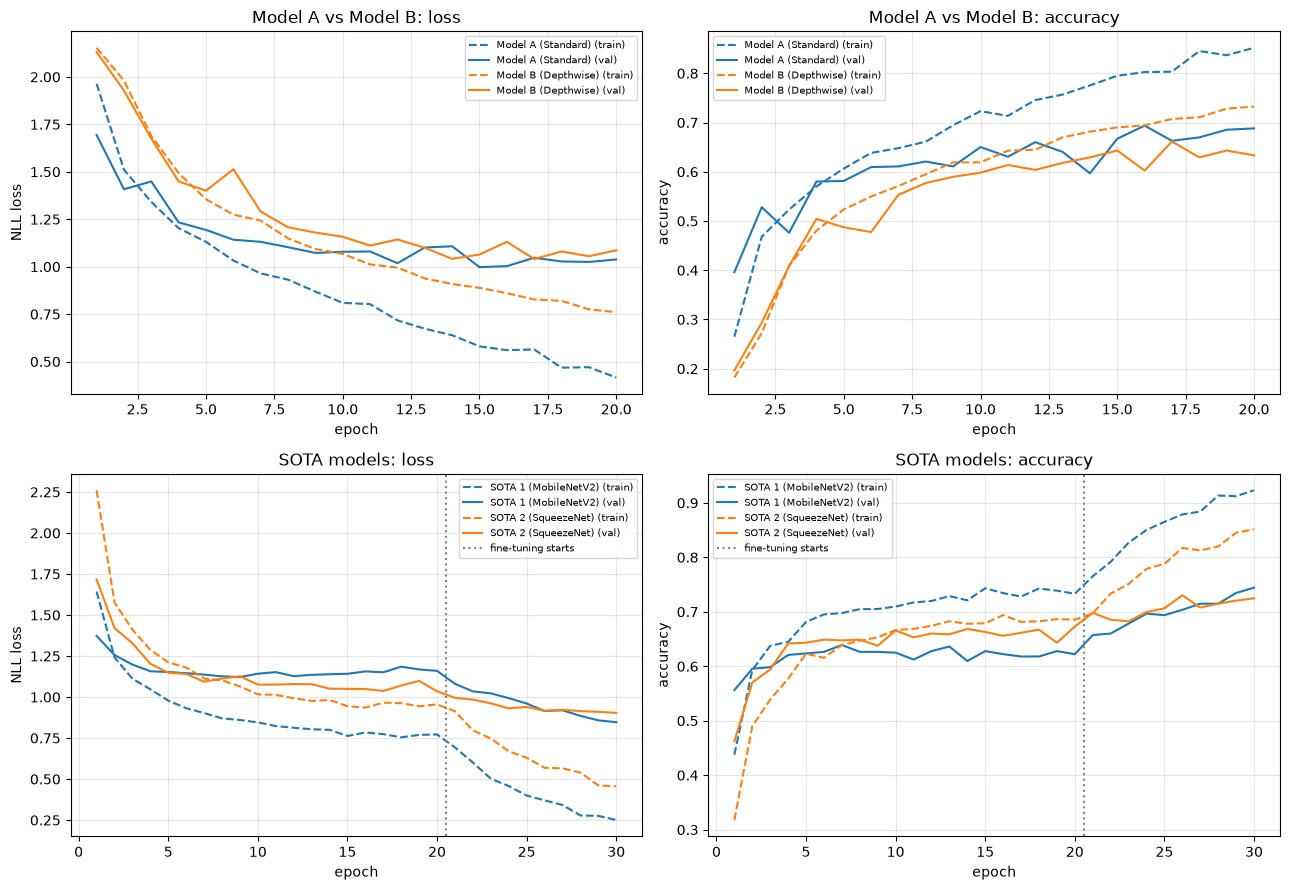

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for row, names in enumerate([custom_names, sota_names]):
    for name in names:
        h = results[name]["history"]
        epochs_range = range(1, len(h["train_loss"]) + 1)
        line, = axes[row, 0].plot(epochs_range, h["train_loss"], linestyle="--", label=f"{name} (train)")
        axes[row, 0].plot(epochs_range, h["val_loss"], color=line.get_color(), label=f"{name} (val)")
        axes[row, 1].plot(epochs_range, h["train_acc"], linestyle="--", color=line.get_color(), label=f"{name} (train)")
        axes[row, 1].plot(epochs_range, h["val_acc"], color=line.get_color(), label=f"{name} (val)")

for ax in axes[1]:
    ax.axvline(EPOCHS + 0.5, color="gray", linestyle=":", label="fine-tuning starts")
for row, title in enumerate(["Model A vs Model B", "SOTA models"]):
    axes[row, 0].set_title(f"{title}: loss"); axes[row, 0].set_ylabel("NLL loss")
    axes[row, 1].set_title(f"{title}: accuracy"); axes[row, 1].set_ylabel("accuracy")
for ax in axes.flat:
    ax.set_xlabel("epoch")
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Test-set evaluation: confusion matrices

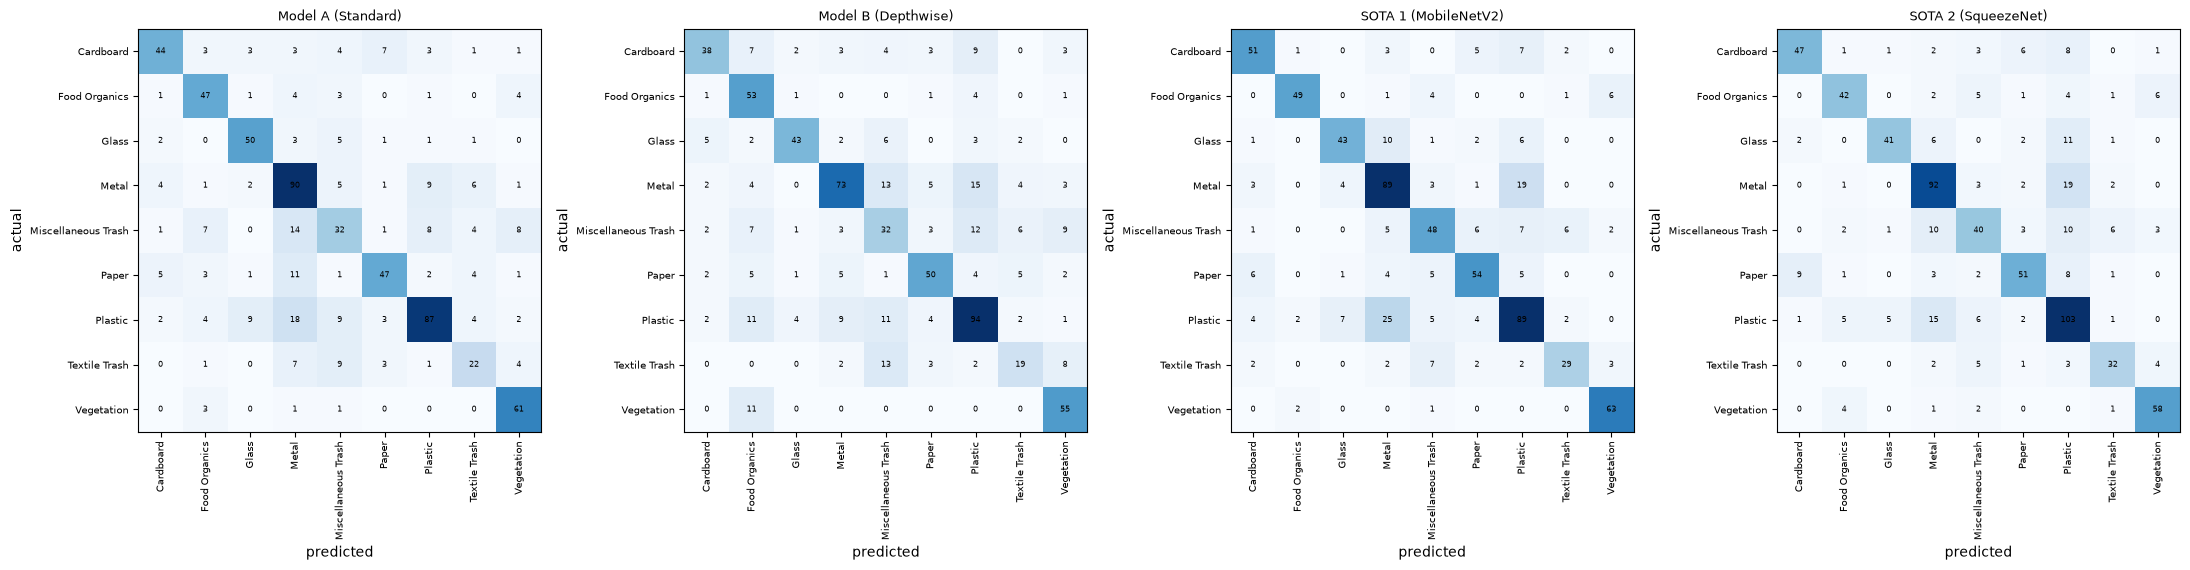

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(22, 5.5))
for ax, (name, r) in zip(axes, results.items()):
    ax.imshow(r["confusion_matrix"], cmap="Blues")
    ax.set_xticks(range(9)); ax.set_xticklabels(CLASS_NAMES, rotation=90, fontsize=7)
    ax.set_yticks(range(9)); ax.set_yticklabels(CLASS_NAMES, fontsize=7)
    ax.set_xlabel("predicted"); ax.set_ylabel("actual")
    ax.set_title(name, fontsize=9)
    for i in range(9):
        for j in range(9):
            ax.text(j, i, r["confusion_matrix"][i, j], ha="center", va="center", fontsize=6)
plt.tight_layout()
plt.show()

### Accuracy, precision and recall

Precision/recall in the tables below are weighted by class size (the classes are imbalanced: Plastic has 921 images, Textile Trash 318). The per-class breakdown shows which classes drive the errors.

In [5]:
for name, r in results.items():
    print(f"=== {name}: accuracy {r['test_accuracy']:.3f}, "
          f"weighted precision {r['precision']:.3f}, weighted recall {r['recall']:.3f}")
    print(r["report"])

=== Model A (Standard): accuracy 0.673, weighted precision 0.678, weighted recall 0.673
                     precision    recall  f1-score   support

          Cardboard      0.746     0.638     0.688        69
      Food Organics      0.681     0.770     0.723        61
              Glass      0.758     0.794     0.775        63
              Metal      0.596     0.756     0.667       119
Miscellaneous Trash      0.464     0.427     0.444        75
              Paper      0.746     0.627     0.681        75
            Plastic      0.777     0.630     0.696       138
      Textile Trash      0.524     0.468     0.494        47
         Vegetation      0.744     0.924     0.824        66

           accuracy                          0.673       713
          macro avg      0.671     0.670     0.666       713
       weighted avg      0.678     0.673     0.670       713

=== Model B (Depthwise): accuracy 0.641, weighted precision 0.655, weighted recall 0.641
                     precis

## 4. Compute cost: MACs and CPU inference latency

`count_macs` counts the multiply-accumulate operations for one 64x64 image with torchinfo. Frozen backbone layers count too: they still run on every inference. Latency is the mean wall-clock time of a forward pass on this machine's CPU (eval mode, after warm-up), for a single image (the edge case: one camera frame at a time) and for a batch of 32. Wall-clock numbers depend on the machine; MACs do not.

In [6]:
for name, model in candidate_models.items():
    r = results[name]
    r["macs"] = count_macs(model, IMG_SIZE)
    r["latency_1_ms"] = inference_latency_ms(model, batch_size=1)
    r["latency_32_ms"] = inference_latency_ms(model, batch_size=32, runs=50)
    print(f"{name:22s} {r['macs'] / 1e6:6.2f} M MACs   {r['latency_1_ms']:6.2f} ms / image   "
          f"{r['latency_32_ms']:6.2f} ms / batch of 32")

Model A (Standard)      11.36 M MACs     0.70 ms / image    16.10 ms / batch of 32


Model B (Depthwise)      3.22 M MACs     1.05 ms / image    15.12 ms / batch of 32


SOTA 1 (MobileNetV2)    24.49 M MACs     8.80 ms / image    39.84 ms / batch of 32


SOTA 2 (SqueezeNet)     17.19 M MACs     3.01 ms / image    32.31 ms / batch of 32


## 5. Task 4: Model A vs Model B

In [7]:
def format_size(size_kb):
    return f"{size_kb / 1024:.2f} MB" if size_kb >= 1024 else f"{size_kb:.1f} KB"


def relative(new, old):
    return f"{(new - old) / old:+.0%}"


a, b = results["Model A (Standard)"], results["Model B (Depthwise)"]
rows = [
    "| | Model A (Standard) | Model B (Depthwise) | B vs A |",
    "|---|---|---|---|",
    f"| Total parameters | {a['total_params']:,} | {b['total_params']:,} | {relative(b['total_params'], a['total_params'])} |",
    f"| Size on disk | {a['size_kb']:.1f} KB | {b['size_kb']:.1f} KB | {relative(b['size_kb'], a['size_kb'])} |",
    f"| MACs / image | {a['macs'] / 1e6:.2f} M | {b['macs'] / 1e6:.2f} M | {relative(b['macs'], a['macs'])} |",
    f"| Training time / epoch (CPU) | {a['avg_epoch_time']:.2f} s | {b['avg_epoch_time']:.2f} s | {relative(b['avg_epoch_time'], a['avg_epoch_time'])} |",
    f"| Inference latency, 1 image (CPU) | {a['latency_1_ms']:.2f} ms | {b['latency_1_ms']:.2f} ms | {relative(b['latency_1_ms'], a['latency_1_ms'])} |",
    f"| Test accuracy | {a['test_accuracy']:.1%} | {b['test_accuracy']:.1%} | {(b['test_accuracy'] - a['test_accuracy']) * 100:+.1f} pts |",
    f"| Weighted precision | {a['precision']:.3f} | {b['precision']:.3f} | {b['precision'] - a['precision']:+.3f} |",
    f"| Weighted recall | {a['recall']:.3f} | {b['recall']:.3f} | {b['recall'] - a['recall']:+.3f} |",
]
display(Markdown("\n".join(rows)))

| | Model A (Standard) | Model B (Depthwise) | B vs A |
|---|---|---|---|
| Total parameters | 60,457 | 40,457 | -33% |
| Size on disk | 239.3 KB | 162.2 KB | -32% |
| MACs / image | 11.36 M | 3.22 M | -72% |
| Training time / epoch (CPU) | 3.53 s | 3.77 s | +7% |
| Inference latency, 1 image (CPU) | 0.70 ms | 1.05 ms | +49% |
| Test accuracy | 67.3% | 64.1% | -3.2 pts |
| Weighted precision | 0.678 | 0.655 | -0.023 |
| Weighted recall | 0.673 | 0.641 | -0.032 |

### Trade-offs of moving to depthwise separable convolutions

Generated from the numbers above, like the final discussion below, so it stays accurate if the notebook is re-run.

In [8]:
model_a, model_b = candidate_models["Model A (Standard)"], candidate_models["Model B (Depthwise)"]
fc_params = sum(p.numel() for p in model_b.fc.parameters())  # same 4096 -> 9 head in both models
conv_a, conv_b = a["total_params"] - fc_params, b["total_params"] - fc_params
conv1_macs = sum(p.numel() for p in model_b.conv1.parameters()) * IMG_SIZE * IMG_SIZE
gap_params = 64 * 9 + 9  # Linear(64 -> 9) after global average pooling
mac_ratio = a["macs"] / b["macs"]
acc_diff = (b["test_accuracy"] - a["test_accuracy"]) * 100
train_gap_a = a["history"]["train_acc"][-1] - a["history"]["val_acc"][-1]
train_gap_b = b["history"]["train_acc"][-1] - b["history"]["val_acc"][-1]
best_val_epoch_b = min(range(EPOCHS), key=lambda e: b["history"]["val_loss"][e]) + 1


def speed(new, old):
    return f"{old / new:.2f}x faster" if new < old else f"{new / old:.2f}x slower"


if acc_diff < 0:
    accuracy_text = (
        f"Model B reaches {b['test_accuracy']:.1%} test accuracy, **{-acc_diff:.1f} points below** Model A "
        f"({a['test_accuracy']:.1%}). A depthwise filter sees only one input channel, and spatial filtering and "
        "channel mixing are learned separately, so a separable block can represent fewer functions than a full 3x3 "
        "conv with the same channel widths."
    )
else:
    accuracy_text = (
        f"Model B reaches {b['test_accuracy']:.1%} test accuracy, {acc_diff:+.1f} points against Model A "
        f"({a['test_accuracy']:.1%}): on this small dataset the reduced capacity of the separable blocks did not cost accuracy."
    )
fit_text = (
    f"After {EPOCHS} epochs Model A fits the training set to {a['history']['train_acc'][-1]:.1%} "
    f"(train/validation gap {train_gap_a:.1%}), Model B to {b['history']['train_acc'][-1]:.1%} (gap {train_gap_b:.1%})"
)
if train_gap_a > train_gap_b and b["history"]["train_acc"][-1] < a["history"]["train_acc"][-1]:
    fit_text += ": Model A is already overfitting, while Model B is still limited by its capacity."
else:
    fit_text += "."
if best_val_epoch_b >= EPOCHS - 2:
    fit_text += (f" Model B's validation loss was still at its lowest in epoch {best_val_epoch_b}, "
                 "so more epochs could recover part of the gap at no extra inference cost.")

latency_speed = a["latency_1_ms"] / b["latency_1_ms"]
if latency_speed < 0.8 * mac_ratio:
    cpu_text = (
        f"On this CPU, Model B is {speed(b['latency_1_ms'], a['latency_1_ms'])} per image "
        f"({b['latency_1_ms']:.2f} vs {a['latency_1_ms']:.2f} ms), "
        f"{speed(b['latency_32_ms'], a['latency_32_ms'])} per batch of 32 and "
        f"{speed(b['avg_epoch_time'], a['avg_epoch_time'])} per training epoch: far from the "
        f"{mac_ratio:.1f}x that the MAC count predicts. A depthwise conv does only 9 multiply-adds per value it "
        "reads, so on a desktop CPU it is limited by memory bandwidth, not arithmetic, and PyTorch's CPU kernels for "
        "grouped convolutions are much less optimised than for dense ones. Each separable block also runs two "
        "kernels instead of one and stores an extra intermediate feature map, which costs even more in the backward "
        "pass during training. MACs are the better predictor on the edge targets this model is meant for: "
        "microcontroller libraries such as CMSIS-NN and mobile NPUs have dedicated depthwise kernels, so there the "
        "MAC reduction translates much more directly into latency and energy."
    )
else:
    cpu_text = (
        f"On this CPU the MAC saving also shows up in wall-clock time: Model B is "
        f"{speed(b['latency_1_ms'], a['latency_1_ms'])} per image and "
        f"{speed(b['avg_epoch_time'], a['avg_epoch_time'])} per training epoch."
    )

discussion_ab = f'''
**What depthwise separable convolutions bought.** Replacing Conv2 and Conv3 with depthwise separable blocks cuts
the convolution parameters from {conv_a:,} to {conv_b:,} ({conv_a / conv_b:.1f}x fewer) and the MACs per image from
{a['macs'] / 1e6:.2f} M to {b['macs'] / 1e6:.2f} M ({mac_ratio:.1f}x fewer). The whole-model parameter saving is
only {1 - b['total_params'] / a['total_params']:.0%} because both models share the same 4096 -> 9 Dense head
({fc_params:,} parameters), which is now {fc_params / b['total_params']:.0%} of Model B. Disk size falls in step with
the parameter count ({a['size_kb']:.1f} KB -> {b['size_kb']:.1f} KB), since a float32 state_dict stores 4 bytes per
parameter. Most of Model B's remaining compute is the standard first conv it keeps
({conv1_macs / 1e6:.2f} M of {b['macs'] / 1e6:.2f} M MACs), because it runs at the full 64x64 resolution.

**What it cost.** {accuracy_text} {fit_text}

**MACs vs wall-clock time.** {cpu_text}

**Summary.** Moving to depthwise separable convolutions traded {abs(acc_diff):.1f} points of accuracy for
{mac_ratio:.1f}x less compute and {1 - b['total_params'] / a['total_params']:.0%} fewer parameters. On a
microcontroller-class device, where MACs drive latency and battery life and the model must fit in flash, Model B is
the better candidate; on a desktop CPU, Model A's extra accuracy comes almost for free. Model B's biggest remaining
memory cost is the Flatten -> Dense head: global average pooling (as MobileNet uses) would shrink it from
{fc_params:,} to {gap_params:,} parameters.
'''
display(Markdown(discussion_ab))


**What depthwise separable convolutions bought.** Replacing Conv2 and Conv3 with depthwise separable blocks cuts
the convolution parameters from 23,584 to 3,584 (6.6x fewer) and the MACs per image from
11.36 M to 3.22 M (3.5x fewer). The whole-model parameter saving is
only 33% because both models share the same 4096 -> 9 Dense head
(36,873 parameters), which is now 91% of Model B. Disk size falls in step with
the parameter count (239.3 KB -> 162.2 KB), since a float32 state_dict stores 4 bytes per
parameter. Most of Model B's remaining compute is the standard first conv it keeps
(1.84 M of 3.22 M MACs), because it runs at the full 64x64 resolution.

**What it cost.** Model B reaches 64.1% test accuracy, **3.2 points below** Model A (67.3%). A depthwise filter sees only one input channel, and spatial filtering and channel mixing are learned separately, so a separable block can represent fewer functions than a full 3x3 conv with the same channel widths. After 20 epochs Model A fits the training set to 85.2% (train/validation gap 16.4%), Model B to 73.2% (gap 9.9%): Model A is already overfitting, while Model B is still limited by its capacity.

**MACs vs wall-clock time.** On this CPU, Model B is 1.49x slower per image (1.05 vs 0.70 ms), 1.06x faster per batch of 32 and 1.07x slower per training epoch: far from the 3.5x that the MAC count predicts. A depthwise conv does only 9 multiply-adds per value it reads, so on a desktop CPU it is limited by memory bandwidth, not arithmetic, and PyTorch's CPU kernels for grouped convolutions are much less optimised than for dense ones. Each separable block also runs two kernels instead of one and stores an extra intermediate feature map, which costs even more in the backward pass during training. MACs are the better predictor on the edge targets this model is meant for: microcontroller libraries such as CMSIS-NN and mobile NPUs have dedicated depthwise kernels, so there the MAC reduction translates much more directly into latency and energy.

**Summary.** Moving to depthwise separable convolutions traded 3.2 points of accuracy for
3.5x less compute and 33% fewer parameters. On a
microcontroller-class device, where MACs drive latency and battery life and the model must fit in flash, Model B is
the better candidate; on a desktop CPU, Model A's extra accuracy comes almost for free. Model B's biggest remaining
memory cost is the Flatten -> Dense head: global average pooling (as MobileNet uses) would shrink it from
36,873 to 585 parameters.


## 6. Task 6: Model B vs the fine-tuned SOTA models

In [9]:
rows = ["| Model | Total params | Trainable params | Size on disk | MACs / image | CPU latency (1 image) "
        "| CPU latency (batch 32) | Train time / epoch | Test accuracy | Precision | Recall |",
        "|---|---|---|---|---|---|---|---|---|---|---|"]
for name, r in results.items():
    trainable = (f"{r['head_params']:,} -> {r['trainable_params']:,}" if name in sota_names
                 else f"{r['trainable_params']:,}")
    rows.append(
        f"| {name} | {r['total_params']:,} | {trainable} | {format_size(r['size_kb'])} | {r['macs'] / 1e6:.2f} M | "
        f"{r['latency_1_ms']:.2f} ms | {r['latency_32_ms']:.1f} ms | {r['avg_epoch_time']:.2f} s | "
        f"{r['test_accuracy']:.1%} | {r['precision']:.3f} | {r['recall']:.3f} |"
    )

summary_table = "\n".join(rows)
display(Markdown(summary_table))

| Model | Total params | Trainable params | Size on disk | MACs / image | CPU latency (1 image) | CPU latency (batch 32) | Train time / epoch | Test accuracy | Precision | Recall |
|---|---|---|---|---|---|---|---|---|---|---|
| Model A (Standard) | 60,457 | 60,457 | 239.3 KB | 11.36 M | 0.70 ms | 16.1 ms | 3.53 s | 67.3% | 0.678 | 0.673 |
| Model B (Depthwise) | 40,457 | 40,457 | 162.2 KB | 3.22 M | 1.05 ms | 15.1 ms | 3.77 s | 64.1% | 0.655 | 0.641 |
| SOTA 1 (MobileNetV2) | 2,235,401 | 11,529 -> 1,217,609 | 8.76 MB | 24.49 M | 8.80 ms | 39.8 ms | 7.50 s | 72.2% | 0.725 | 0.722 |
| SOTA 2 (SqueezeNet) | 727,113 | 4,617 -> 390,793 | 2.79 MB | 17.19 M | 3.01 ms | 32.3 ms | 4.15 s | 71.0% | 0.716 | 0.710 |

### Trade-off discussion

Generated from the actual numbers above, so it stays accurate to whatever hardware this notebook is run on. For the SOTA models, "Trainable params" shows stage 1 (head only) -> stage 2 (fine-tuning), and the training time is averaged over both stages.

In [10]:
b = results["Model B (Depthwise)"]
best_sota = max(sota_names, key=lambda n: results[n]["test_accuracy"])
best_acc_name = max(results, key=lambda n: results[n]["test_accuracy"])
fastest_name = min(results, key=lambda n: results[n]["latency_1_ms"])
quickest_sota_ms = min(results[n]["latency_1_ms"] for n in sota_names)

comparison = "\n".join(
    f"- **{n}** vs Model B: {(results[n]['test_accuracy'] - b['test_accuracy']) * 100:+.1f} points accuracy, "
    f"{results[n]['total_params'] / b['total_params']:.0f}x the parameters, "
    f"{results[n]['size_kb'] / b['size_kb']:.0f}x the disk size, "
    f"{results[n]['macs'] / b['macs']:.1f}x the MACs, "
    f"{results[n]['latency_1_ms'] / b['latency_1_ms']:.1f}x the single-image CPU latency."
    for n in sota_names
)

sota_gain = (results[best_sota]["test_accuracy"] - b["test_accuracy"]) * 100
if sota_gain > 0:
    accuracy_text = (
        f"The pretrained models win on accuracy: {best_sota} reaches {results[best_sota]['test_accuracy']:.1%}, "
        f"{sota_gain:.1f} points above Model B. Its backbone starts from features learned on 1.2 M ImageNet images, "
        "while Model B has to learn every filter from ~3.3k training images."
    )
else:
    accuracy_text = (
        f"Model B holds its own: the best fine-tuned SOTA model ({best_sota}, "
        f"{results[best_sota]['test_accuracy']:.1%}) is {-sota_gain:.1f} points behind it."
    )
accuracy_text += (
    " The SOTA models are also handicapped here: both were pretrained at 224x224, and at 64x64 MobileNetV2's 32x "
    "downsampling leaves only a 2x2 feature map, so much of what the backbone learned goes unused. Feeding them "
    "224x224 images would likely raise their accuracy, but would also multiply their MACs by about "
    f"(224/64)^2 = {(224 / 64) ** 2:.1f}x."
)

if sota_gain > 0:
    cost_text = f"at a cost of {sota_gain:.1f} points of accuracy against the best fine-tuned SOTA model ({best_sota})"
else:
    cost_text = "while matching or beating both fine-tuned SOTA models on accuracy"

if fastest_name == "Model B (Depthwise)":
    latency_text = "Model B also has the lowest measured single-image latency of the four on this CPU."
else:
    latency_text = (
        f"On this CPU, {fastest_name} has the lowest single-image latency ({results[fastest_name]['latency_1_ms']:.2f} ms "
        f"vs Model B's {b['latency_1_ms']:.2f} ms): the MAC saving of depthwise convolutions does not fully show up "
        f"on a desktop CPU (Section 5), but Model B is still {quickest_sota_ms / b['latency_1_ms']:.1f}x faster "
        "than the quicker SOTA model."
    )

discussion = f'''
{comparison}

**Accuracy.** {accuracy_text}

**Memory footprint.** Model B is {format_size(b['size_kb'])} as float32 and about {b['total_params'] / 1024:.0f} KB
after int8 quantization (1 byte per weight), small enough for the flash of a typical microcontroller (often
256 KB - 2 MB) with room left for the application. MobileNetV2 needs
{format_size(results['SOTA 1 (MobileNetV2)']['size_kb'])} (~{results['SOTA 1 (MobileNetV2)']['total_params'] / 1024 ** 2:.1f} MB int8)
and SqueezeNet {format_size(results['SOTA 2 (SqueezeNet)']['size_kb'])}
(~{results['SOTA 2 (SqueezeNet)']['total_params'] / 1024 ** 2:.1f} MB int8), which points to a Raspberry Pi or
phone-class device. Freezing or partly fine-tuning a backbone reduces *training* cost only: every backbone weight
still has to ship with the model.

**Computational cost.** Per 64x64 image, Model B needs {b['macs'] / 1e6:.2f} M MACs against
{results['SOTA 1 (MobileNetV2)']['macs'] / 1e6:.2f} M for MobileNetV2 and
{results['SOTA 2 (SqueezeNet)']['macs'] / 1e6:.2f} M for SqueezeNet. The SOTA backbones pay that full cost on every
inference, however few of their weights were trained. Measured single-image CPU latency is
{b['latency_1_ms']:.2f} ms for Model B vs {results['SOTA 1 (MobileNetV2)']['latency_1_ms']:.2f} ms (MobileNetV2) and
{results['SOTA 2 (SqueezeNet)']['latency_1_ms']:.2f} ms (SqueezeNet). {latency_text}

**Custom sub-100k model vs pretrained model.** Building from scratch lets every choice follow the target device:
the parameter budget is met by construction, every layer is a cheap operation (ReLU, depthwise convs, one Softmax),
and the model is trained at the resolution it runs at. The price is accuracy and engineering effort: all features
are learned from a small dataset, and the architecture and training need tuning by hand. A pretrained lightweight
model gets strong, general features and a proven architecture (with existing quantization and deployment tooling)
almost for free, but its minimum size and compute are fixed by the architecture, not by the task, and at a
non-native input resolution part of its pretrained knowledge is wasted.

**Conclusion.** Model B has the fewest MACs and the smallest memory footprint of all four models, {cost_text}.
The most accurate model overall is {best_acc_name} ({results[best_acc_name]['test_accuracy']:.1%}). For a
microcontroller-class target with a small flash and compute budget and no accelerator, Model B is the practical
choice. {best_sota} is worth {results[best_sota]['macs'] / b['macs']:.1f}x the compute and
{results[best_sota]['size_kb'] / b['size_kb']:.0f}x the memory of Model B only when the device has that headroom and
the application needs the extra accuracy.
'''

display(Markdown(discussion))


- **SOTA 1 (MobileNetV2)** vs Model B: +8.1 points accuracy, 55x the parameters, 55x the disk size, 7.6x the MACs, 8.4x the single-image CPU latency.
- **SOTA 2 (SqueezeNet)** vs Model B: +6.9 points accuracy, 18x the parameters, 18x the disk size, 5.3x the MACs, 2.9x the single-image CPU latency.

**Accuracy.** The pretrained models win on accuracy: SOTA 1 (MobileNetV2) reaches 72.2%, 8.1 points above Model B. Its backbone starts from features learned on 1.2 M ImageNet images, while Model B has to learn every filter from ~3.3k training images. The SOTA models are also handicapped here: both were pretrained at 224x224, and at 64x64 MobileNetV2's 32x downsampling leaves only a 2x2 feature map, so much of what the backbone learned goes unused. Feeding them 224x224 images would likely raise their accuracy, but would also multiply their MACs by about (224/64)^2 = 12.2x.

**Memory footprint.** Model B is 162.2 KB as float32 and about 40 KB
after int8 quantization (1 byte per weight), small enough for the flash of a typical microcontroller (often
256 KB - 2 MB) with room left for the application. MobileNetV2 needs
8.76 MB (~2.1 MB int8)
and SqueezeNet 2.79 MB
(~0.7 MB int8), which points to a Raspberry Pi or
phone-class device. Freezing or partly fine-tuning a backbone reduces *training* cost only: every backbone weight
still has to ship with the model.

**Computational cost.** Per 64x64 image, Model B needs 3.22 M MACs against
24.49 M for MobileNetV2 and
17.19 M for SqueezeNet. The SOTA backbones pay that full cost on every
inference, however few of their weights were trained. Measured single-image CPU latency is
1.05 ms for Model B vs 8.80 ms (MobileNetV2) and
3.01 ms (SqueezeNet). On this CPU, Model A (Standard) has the lowest single-image latency (0.70 ms vs Model B's 1.05 ms): the MAC saving of depthwise convolutions does not fully show up on a desktop CPU (Section 5), but Model B is still 2.9x faster than the quicker SOTA model.

**Custom sub-100k model vs pretrained model.** Building from scratch lets every choice follow the target device:
the parameter budget is met by construction, every layer is a cheap operation (ReLU, depthwise convs, one Softmax),
and the model is trained at the resolution it runs at. The price is accuracy and engineering effort: all features
are learned from a small dataset, and the architecture and training need tuning by hand. A pretrained lightweight
model gets strong, general features and a proven architecture (with existing quantization and deployment tooling)
almost for free, but its minimum size and compute are fixed by the architecture, not by the task, and at a
non-native input resolution part of its pretrained knowledge is wasted.

**Conclusion.** Model B has the fewest MACs and the smallest memory footprint of all four models, at a cost of 8.1 points of accuracy against the best fine-tuned SOTA model (SOTA 1 (MobileNetV2)).
The most accurate model overall is SOTA 1 (MobileNetV2) (72.2%). For a
microcontroller-class target with a small flash and compute budget and no accelerator, Model B is the practical
choice. SOTA 1 (MobileNetV2) is worth 7.6x the compute and
55x the memory of Model B only when the device has that headroom and
the application needs the extra accuracy.
